# Healthcare Analytics for Doctor Visits
**Edunet Foundation | Data Analytics Project**

## 1. Problem Statement
Why do some people visit a doctor more often than others? This project analyses 5,190 patient records to find which personal, health, financial and healthcare-support factors are associated with the number of doctor visits, and builds simple models that predict visits.

## 2. Objectives
1. Clean and understand the dataset.
2. Explore how visits relate to age, gender, income, illness, health, activity reduction, chronic conditions and healthcare support.
3. Test the differences statistically.
4. Build models to (a) predict the number of visits and (b) predict whether a person visits a doctor at all.
5. Summarise findings and recommendations.

## 3. Import Libraries and Load Data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix
sns.set_theme(style='whitegrid')

df = pd.read_csv('1776250375-P2-Healthcare_Analytics_for_Doctor_Visits.csv')
print(df.shape)
df.head()

(5190, 13)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


## 4. Data Understanding and Cleaning

In [2]:
df = df.drop(columns='Unnamed: 0')     # record identifier, not a healthcare measurement
print(df.info())
print('\nMissing values:\n', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df.describe(include='all').T

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   visits     5190 non-null   int64  
 1   gender     5190 non-null   str    
 2   age        5190 non-null   float64
 3   income     5190 non-null   float64
 4   illness    5190 non-null   int64  
 5   reduced    5190 non-null   int64  
 6   health     5190 non-null   int64  
 7   private    5190 non-null   str    
 8   freepoor   5190 non-null   str    
 9   freerepat  5190 non-null   str    
 10  nchronic   5190 non-null   str    
 11  lchronic   5190 non-null   str    
dtypes: float64(2), int64(4), str(6)
memory usage: 486.7 KB
None

Missing values:
 0
Duplicate rows: 1320


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
visits,5190.0,NaN,NaN,NaN,0.301734,0.798134,0.0,0.0,0.0,0.0,9.0
gender,5190,2,female,2702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5190.0,NaN,NaN,NaN,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,NaN,NaN,NaN,0.58316,0.368907,0.0,0.25,0.55,0.9,1.5
illness,5190.0,NaN,NaN,NaN,1.431985,1.384152,0.0,0.0,1.0,2.0,5.0
reduced,5190.0,NaN,NaN,NaN,0.86185,2.887628,0.0,0.0,0.0,0.0,14.0
health,5190.0,NaN,NaN,NaN,1.217534,2.124266,0.0,0.0,0.0,2.0,12.0
private,5190,2,no,2892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freepoor,5190,2,no,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freerepat,5190,2,no,4099,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**
- No missing values, so no imputation is needed. `Unnamed: 0` is only a row ID and was dropped.
- 1,320 rows are exact duplicates. Because `age` and `income` are recorded in coarse steps, different people can have identical values, so these are **kept** (they are not data-entry errors).
- `age` is stored as years/100 (0.19 to 0.72, i.e. about 19 to 72 years) and `income` as a scaled value (0 to 1.5). I convert age to years for readability.

In [3]:
df['age_years'] = (df['age']*100).round().astype(int)
df['age_group'] = pd.cut(df['age_years'], [0,20,30,50,70,100], labels=['<=20','21-30','31-50','51-70','>70'])
df['any_visit'] = (df['visits']>0).astype(int)
cat_cols = ['gender','private','freepoor','freerepat','nchronic','lchronic']
print('Mean visits:', round(df.visits.mean(),3), '| Variance:', round(df.visits.var(),3))
print('Share with at least one visit:', round(df.any_visit.mean()*100,1), '%')

Mean visits: 0.302 | Variance: 0.637
Share with at least one visit: 20.2 %


## 5. Exploratory Data Analysis

### 5.1 Target variable: doctor visits

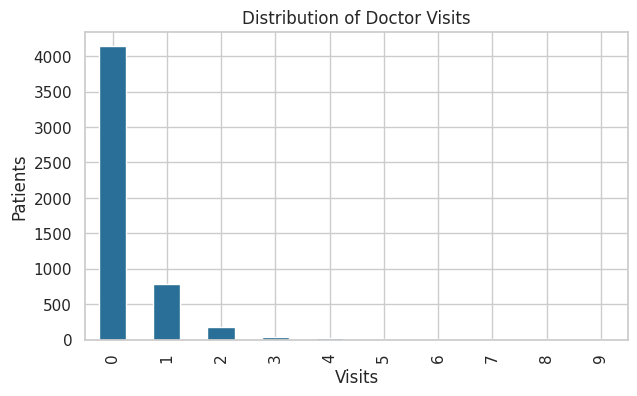

visits
0    79.8
1    15.1
2     3.4
3     0.6
4     0.5
5     0.2
6     0.2
7     0.2
8     0.1
9     0.0
Name: count, dtype: float64


In [4]:
counts = df.visits.value_counts().sort_index()
ax = counts.plot.bar(color='#2a6f97', figsize=(7,4)); ax.set_title('Distribution of Doctor Visits'); ax.set_xlabel('Visits'); ax.set_ylabel('Patients')
plt.show(); print((counts/len(df)*100).round(1))

About **80% of people made no visit**, and the distribution is heavily right-skewed. The variance (0.64) is about double the mean (0.30), so the data is **over-dispersed count data**. This is why count-based models and non-parametric tests are used later.

### 5.2 Distribution of key numeric variables

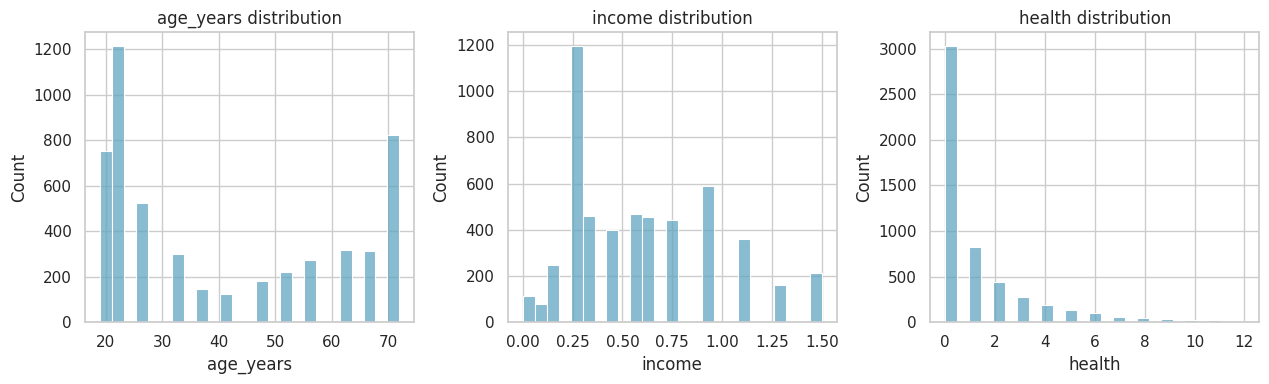

In [5]:
fig, axs = plt.subplots(1,3,figsize=(13,4))
for ax,c in zip(axs,['age_years','income','health']):
    sns.histplot(df[c], bins=25, ax=ax, color='#61a5c2'); ax.set_title(c+' distribution')
plt.tight_layout(); plt.show()

### 5.3 Visits by gender, insurance/support and chronic conditions

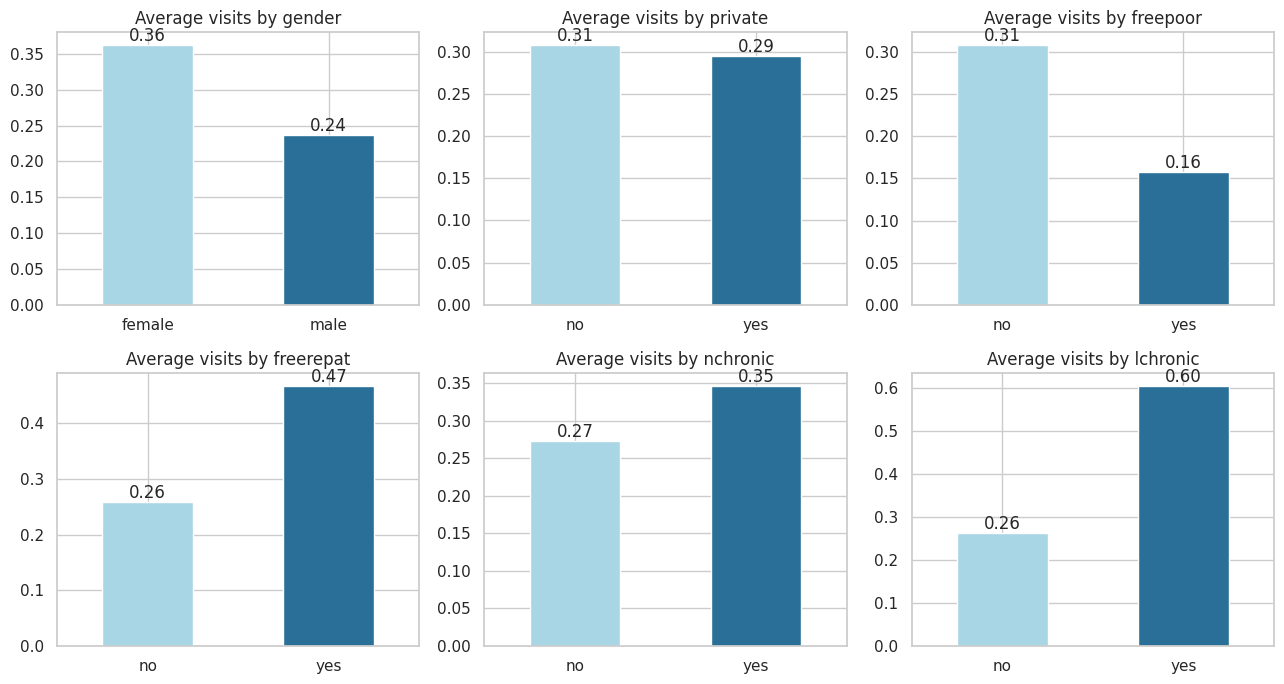

In [6]:
fig, axs = plt.subplots(2,3,figsize=(13,7))
for ax,c in zip(axs.ravel(), cat_cols):
    m = df.groupby(c).visits.mean(); m.plot.bar(ax=ax, color=['#a9d6e5','#2a6f97']); ax.set_title(f'Average visits by {c}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
    for i,v in enumerate(m): ax.text(i, v, f'{v:.2f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

- **Women** visit more than men (0.36 vs 0.24).
- People with a **limiting chronic condition** (`lchronic`) average 0.60 visits versus 0.26 without.
- **freerepat** (repatriation cover) holders visit more (0.47 vs 0.26); **freepoor** (free cover for low income) visit *less* (0.16 vs 0.31).
- **Private insurance** shows almost no difference (0.29 vs 0.31).

### 5.4 Visits vs illness, health score and days of reduced activity

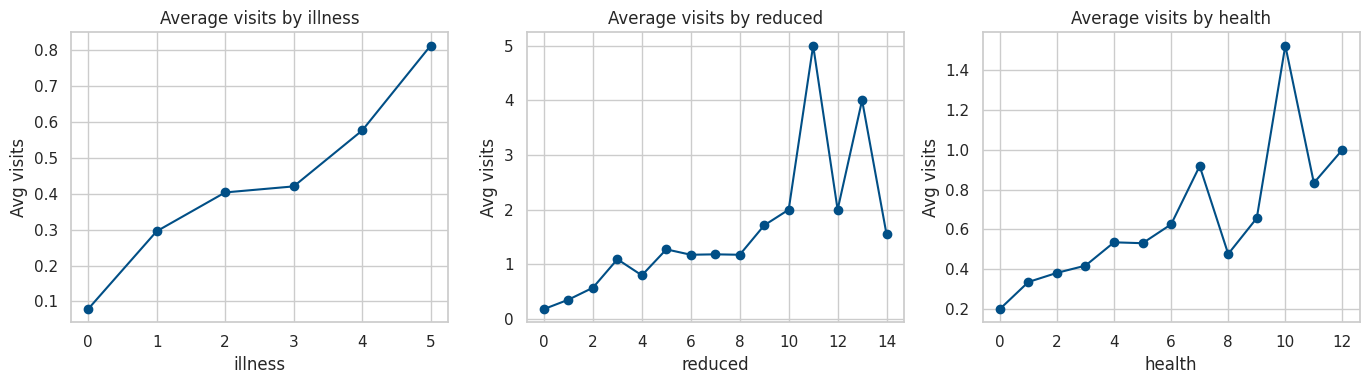

In [7]:
fig, axs = plt.subplots(1,3,figsize=(14,4))
for ax,c in zip(axs,['illness','reduced','health']):
    df.groupby(c).visits.mean().plot(marker='o', ax=ax, color='#014f86'); ax.set_title(f'Average visits by {c}'); ax.set_ylabel('Avg visits')
plt.tight_layout(); plt.show()

Visits rise steadily with the number of illnesses (0.08 with none, 0.81 with five) and with days of reduced activity (0.18 with none, about 1.5 at the 14-day maximum). The pattern is much sharper for `reduced` than for any other variable.

### 5.5 Visits by age group

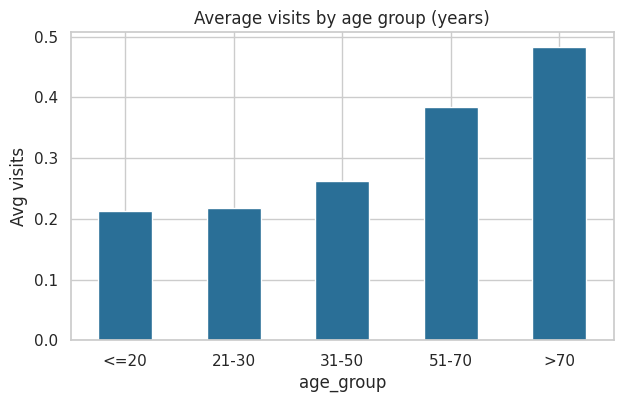

In [8]:
ax = df.groupby('age_group', observed=True).visits.mean().plot.bar(color='#2a6f97', figsize=(7,4)); ax.set_title('Average visits by age group (years)'); ax.set_ylabel('Avg visits'); ax.tick_params(axis='x', rotation=0)
plt.show()

Average visits climb with age: 0.21 for those 20 and under to 0.48 for those over 70.

### 5.6 Correlation

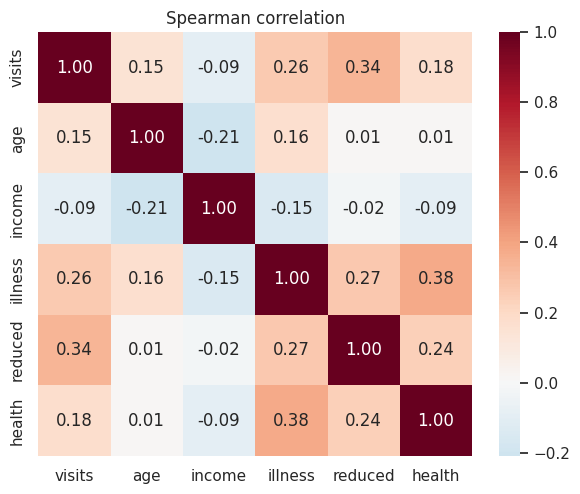

In [9]:
num = ['visits','age','income','illness','reduced','health']
plt.figure(figsize=(7,5.5)); sns.heatmap(df[num].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Spearman correlation'); plt.show()

`reduced` (0.34) and `illness` (0.26) have the strongest correlation with visits, then `health` (0.18) and `age` (0.15). `income` is weakly negative (-0.09). Higher-income people are slightly less likely to visit, mostly because they are younger and healthier (income correlates -0.21 with age and -0.15 with illness).

## 6. Statistical Testing

Mann-Whitney U tests (suitable for skewed count data) compare visits between the two groups of each yes/no column.

In [10]:
rows=[]
for c in cat_cols:
    v = df[c].unique(); a = df[df[c]==v[0]].visits; b = df[df[c]==v[1]].visits
    rows.append([c, f'{v[0]} vs {v[1]}', round(a.mean(),3), round(b.mean(),3), stats.mannwhitneyu(a,b).pvalue])
t = pd.DataFrame(rows, columns=['variable','groups','mean_1','mean_2','p_value']); t['significant (p<0.05)'] = t.p_value<0.05
t

,variable,groups,mean_1,mean_2,p_value,significant (p<0.05)
0,gender,female vs male,0.362,0.236,6.338282e-15,True
1,private,yes vs no,0.295,0.307,7.615255e-01,False
2,freepoor,no vs yes,0.308,0.158,2.481977e-05,True
3,freerepat,no vs yes,0.258,0.467,1.500683e-25,True
4,nchronic,no vs yes,0.272,0.346,5.744675e-07,True
5,lchronic,no vs yes,0.262,0.603,1.197079e-23,True


All variables are significantly associated with visits **except private insurance** (p = 0.76).

## 7. Model 1: Poisson Regression (explaining visits)

In [11]:
X = pd.get_dummies(df[['gender','age','income','illness','reduced','health','private','freepoor','freerepat','nchronic','lchronic']], drop_first=True).astype(float)
pm = sm.GLM(df.visits, sm.add_constant(X), family=sm.families.Poisson()).fit()
out = pd.DataFrame({'coef':pm.params, 'p_value':pm.pvalues, 'rate_ratio':np.exp(pm.params)}).round(3)
out

,coef,p_value,rate_ratio
const,-1.941,0.000,0.144
age,0.279,0.093,1.322
income,-0.187,0.028,0.829
illness,0.186,0.000,1.205
reduced,0.127,0.000,1.135
health,0.031,0.002,1.031
gender_male,-0.156,0.005,0.855
private_yes,0.126,0.077,1.135
freepoor_yes,-0.438,0.015,0.645
freerepat_yes,0.084,0.364,1.087


**How to read it:** a rate ratio above 1 means more visits, below 1 means fewer, holding everything else fixed.
- Each extra **day of reduced activity** raises expected visits by about **13.5%**, and each extra **illness** by about **20%**.
- **Men** have about 14% fewer visits than women; **freepoor** holders about 35% fewer; each unit of **income** about 17% fewer.
- Once health is accounted for, `freerepat`, `private` and the chronic flags are **not** significant at 5%. The raw gap for repatriation cover is explained by those people being less healthy.

## 8. Model 2: Predicting the number of visits

In [12]:
Xtr, Xte, ytr, yte = train_test_split(X, df.visits, test_size=0.2, random_state=42)
base = np.full(len(yte), ytr.mean())
poi = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=500)).fit(Xtr, ytr)
rf  = RandomForestRegressor(300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(Xtr, ytr)
res = {}
for n,p in [('Baseline (mean)',base),('Poisson Regression',poi.predict(Xte)),('Random Forest',rf.predict(Xte))]:
    res[n] = [mean_absolute_error(yte,p), np.sqrt(mean_squared_error(yte,p)), r2_score(yte,p)]
pd.DataFrame(res, index=['MAE','RMSE','R2']).T.round(3)

,MAE,RMSE,R2
Baseline (mean),0.516,0.943,-0.005
Poisson Regression,0.470,0.889,0.106
Random Forest,0.412,0.833,0.215


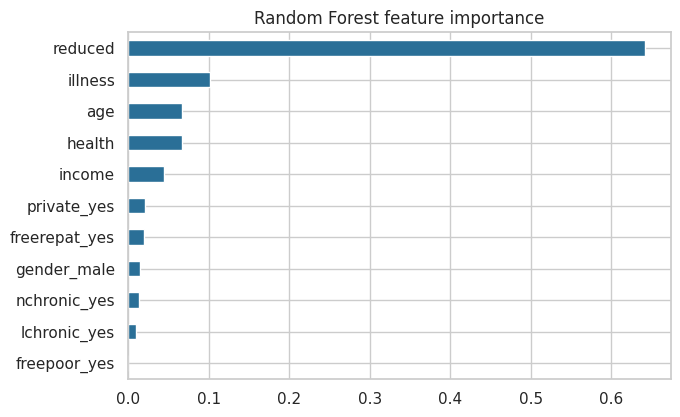

In [13]:
fi = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
fi.plot.barh(figsize=(7,4.5), color='#2a6f97'); plt.title('Random Forest feature importance'); plt.show()

The Random Forest is best (MAE 0.41 vs 0.52 for the baseline, R² about 0.22). R² is modest, which is expected: a person's visits depend on many things not in this dataset. **Days of reduced activity** is by far the most important predictor, followed by illness count, age and health score.

## 9. Model 3: Will a person visit a doctor at all?

In [14]:
yb = df.any_visit
Xtr, Xte, ytr, yte = train_test_split(X, yb, test_size=0.2, random_state=42, stratify=yb)
lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')).fit(Xtr, ytr)
rc = RandomForestClassifier(300, min_samples_leaf=15, random_state=42, class_weight='balanced', n_jobs=-1).fit(Xtr, ytr)
cl = {}
for n,m in [('Logistic Regression',lg),('Random Forest',rc)]:
    cl[n] = [accuracy_score(yte,m.predict(Xte)), f1_score(yte,m.predict(Xte)), roc_auc_score(yte,m.predict_proba(Xte)[:,1])]
print(pd.DataFrame(cl, index=['Accuracy','F1','ROC-AUC']).T.round(3))
print('\nConfusion matrix (Random Forest):\n', confusion_matrix(yte, rc.predict(Xte)))

                     Accuracy     F1  ROC-AUC
Logistic Regression     0.716  0.459    0.736
Random Forest           0.721  0.469    0.744

Confusion matrix (Random Forest):
 [[620 208]
 [ 82 128]]


Both classifiers reach about 72% accuracy and ROC-AUC of about 0.74, so the data separates visitors from non-visitors reasonably well but not perfectly. Class weighting was used because only 20% of people visit.

## 10. Patient Risk Segmentation

In [15]:
df['risk_score'] = df.illness + df.reduced/2 + df.health/2
df['risk'] = pd.cut(df.risk_score, [-1,1,3,100], labels=['Low','Medium','High'])
seg = df.groupby('risk', observed=True).agg(patients=('visits','count'), avg_visits=('visits','mean'), pct_with_visit=('any_visit','mean'))
seg['pct_with_visit'] = (seg.pct_with_visit*100).round(1); seg['avg_visits'] = seg.avg_visits.round(2)
seg

,patients,avg_visits,pct_with_visit
risk,,,
Low,2361,0.10,8.7
Medium,1477,0.27,21.4
High,1352,0.69,39.0


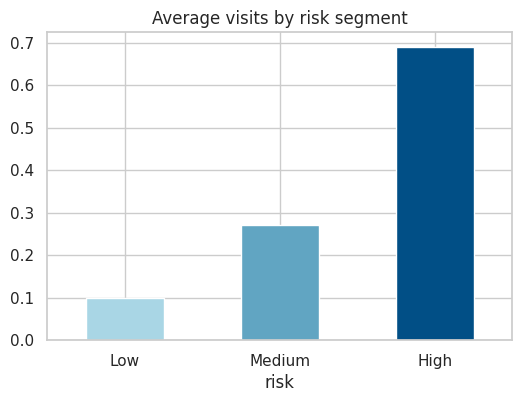

In [16]:
seg.avg_visits.plot.bar(color=['#a9d6e5','#61a5c2','#014f86'], figsize=(6,4)); plt.title('Average visits by risk segment'); plt.xticks(rotation=0); plt.show()

A simple health-burden score (illnesses + half of reduced-activity days + half of the health score) splits patients into three groups. The **High** group averages about **0.69 visits, roughly 7 times the Low group (0.10)**. This is a practical way to flag people likely to need more care.

## 11. Key Findings
1. **80% of people did not visit a doctor**; visits are skewed and over-dispersed.
2. **Health burden is the main driver**: days of reduced activity, number of illnesses and the general health score are the strongest predictors.
3. **Age**: visits rise from 0.21 (20 and under) to 0.48 (over 70).
4. **Gender**: women visit about 50% more than men in raw terms (0.36 vs 0.24), and about 17% more after adjustment.
5. **Healthcare support**: free cover for low-income people (`freepoor`) is linked with fewer visits; private insurance makes no real difference.
6. **Income** has a small negative association with visits.
7. A Random Forest predicts visits better than the baseline (MAE 0.41 vs 0.52) and classifies visitors vs non-visitors with ROC-AUC about 0.74.

## 12. Recommendations
- Use the risk score (illness, reduced-activity days, health score) to prioritise outreach to high-risk patients.
- Look at why low-income `freepoor` patients visit less despite free cover. This may point to access barriers worth investigating.
- Plan capacity around older patients and women, who have the highest visit rates.
- Collect richer data (diagnosis, visit cost, region, time period) to improve prediction.

## 13. Limitations
- The data shows **association, not causation**.
- Model R² is modest because key drivers of visits are not in the dataset.
- `age`, `income` and `health` are coded values without published units, so interpretation uses relative differences.
- Duplicate-looking rows were kept as genuinely different people.

## 14. Conclusion
Doctor visits are driven mainly by how unwell a person is, with age, gender and the type of healthcare support playing smaller roles. A simple risk score and a Random Forest model can identify people likely to need more care.